In [ ]:
# @title
kpss_values = {
    "AQI.json": 2.32,
    "Antam.json": 2.36,
    "Bitcoin_close.json": 1.73,
    "Bitcoin_high.json": 1.73,
    "Bitcoin_low.json": 1.75,
    "Bitcoin_open.json": 1.75,
    "Bitcoin_volume.json": 1.22,
    "Daily_caffeine_mg.json": 0.15,
    "Daily_dbp_mmHg.json": 0.17,
    "Daily_resting_hr_bpm.json": 0.05,
    "Daily_sbp_mmHg.json": 0.06,
    "Daily_spo2_avg_pct.json": 0.11,
    "Daily_stress_score.json": 0.03,
    "Dhaka.json": 1.53,
    "WB_air_pressure.json": 1.40,
    "WB_air_temp.json": 0.36,
    "WB_air_wind_speed.json": 0.37,
    "WB_bod.json": 0.11,
    "WB_cl.json": 2.90,
    "WB_cod.json": 1.57,
    "WB_do.json": 2.72,
    "WB_humidity.json": 0.15,
    "WB_ph.json": 3.82,
    "WB_temperature.json": 0.42,
    "WB_toc.json": 1.60,
    "WB_wt.json": 2.11
}

R ADF

In [ ]:
# @title

adf_values = {
    "AQI.json": -4.36,
    "Antam.json": -0.49,
    "Bitcoin_close.json": -1.60,
    "Bitcoin_high.json": -1.69,
    "Bitcoin_low.json": -1.72,
    "Bitcoin_open.json": -1.66,
    "Bitcoin_volume.json": -9.36,
    "Daily_caffeine_mg.json": -9.35,
    "Daily_dbp_mmHg.json": -9.93,
    "Daily_resting_hr_bpm.json": -8.89,
    "Daily_sbp_mmHg.json": -10.61,
    "Daily_spo2_avg_pct.json": -10.14,
    "Daily_stress_score.json": -10.15,
    "Dhaka.json": -4.64,
    "WB_air_pressure.json": -5.65,
    "WB_air_temp.json": -7.49,
    "WB_air_wind_speed.json": -4.87,
    "WB_bod.json": -14.47,
    "WB_cl.json": -4.18,
    "WB_cod.json": -14.05,
    "WB_do.json": -6.08,
    "WB_humidity.json": -7.13,
    "WB_ph.json": -12.82,
    "WB_temperature.json": -8.45,
    "WB_toc.json": -13.84,
    "WB_wt.json": -5.16
}


In [ ]:
# @title
f_values = {
    "AQI.json": 0.40,
    "Antam.json": 0.53,
    "Bitcoin_close.json": 0.69,
    "Bitcoin_high.json": 0.68,
    "Bitcoin_low.json": 0.69,
    "Bitcoin_open.json": 0.68,
    "Bitcoin_volume.json": 0.21,
    "Daily_caffeine_mg.json": 0.09,
    "Daily_dbp_mmHg.json": 0.08,
    "Daily_resting_hr_bpm.json": 0.08,
    "Daily_sbp_mmHg.json": 0.07,
    "Daily_spo2_avg_pct.json": 0.10,
    "Daily_stress_score.json": 0.07,
    "Dhaka.json": 0.30,
    "WB_air_pressure.json": 0.07,
    "WB_air_temp.json": 0.58,
    "WB_air_wind_speed.json": 0.43,
    "WB_bod.json": 0.14,
    "WB_cl.json": 0.54,
    "WB_cod.json": 0.17,
    "WB_do.json": 0.44,
    "WB_humidity.json": 0.52,
    "WB_ph.json": 0.22,
    "WB_temperature.json": 0.59,
    "WB_toc.json": 0.15,
    "WB_wt.json": 0.45
}


In [ ]:
# @title
import os
import json
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
models = [
    "TimesFM",
    "Timer",
    "Moirai",
    "Lag_Llama",
    "Chronos",
    "AutoETS",
    "SNaive",
    "AutoARIMA"
]

base_root = "/content/drive/MyDrive/results/paper/json"
rows = []
for model in models:
    model_path = os.path.join(base_root, model)

    if not os.path.isdir(model_path):
        print(f"❌ پوشه پیدا نشد: {model}")
        continue

    json_files = [f for f in os.listdir(model_path) if f.endswith(".json")]
    print(f"📁 {model} | {len(json_files)} فایل")

    for file_name in json_files:
        file_path = os.path.join(model_path, file_name)

        try:
            with open(file_path, "r") as f:
                data = json.load(f)

            if len(data) == 0:
                continue

            run = data[-1]
            metrics = run.get("metrics", {})

            rows.append({
                "model": model,
                "file_name": file_name,
                "mae_scaled": metrics.get("mae_scaled"),
                "rmse_scaled": metrics.get("rmse_scaled"),
                "mse_scaled": metrics.get("mse_scaled"),
                "mase": metrics.get("mase"),
                "crps": metrics.get("crps")
            })

        except Exception as e:
            print(f"⚠️ خطا | {model}/{file_name}: {e}")


df_metrics = pd.DataFrame(rows)



df_metrics["ADF"] = df_metrics["file_name"].map(adf_values)
df_metrics["KPSS"] = df_metrics["file_name"].map(kpss_values)
df_metrics["FCA"] = df_metrics["file_name"].map(f_values)



dataset_order = sorted(df_metrics["file_name"].unique())

dataset_id_map = {
    name: idx + 1
    for idx, name in enumerate(dataset_order)
}

df_metrics["dataset_id"] = df_metrics["file_name"].map(dataset_id_map)


df_metrics = df_metrics.sort_values(
    by=["dataset_id", "model"],
    ascending=[True, True]
)


df_metrics = df_metrics.round(3)


output_path = "/content/drive/MyDrive/results/paper/All_models_metrics_summary.xlsx"
df_metrics.to_excel(output_path, index=False)

print("✅")
print(output_path)

df_metrics


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📁 TimesFM | 26 فایل
📁 Timer | 26 فایل
📁 Moirai | 26 فایل
📁 Lag_Llama | 26 فایل
📁 Chronos | 26 فایل
📁 AutoETS | 26 فایل
📁 SNaive | 26 فایل
📁 AutoARIMA | 26 فایل
✅
/content/drive/MyDrive/results/paper/All_models_metrics_summary.xlsx


,model,file_name,mae_scaled,rmse_scaled,mse_scaled,mase,crps,ADF,KPSS,FCA,dataset_id
206,AutoARIMA,AQI.json,0.100,0.135,0.018,1.752,NaN,-4.36,2.32,0.40,1
154,AutoETS,AQI.json,0.060,0.098,0.010,1.052,NaN,-4.36,2.32,0.40,1
128,Chronos,AQI.json,0.052,0.086,0.007,0.899,0.197,-4.36,2.32,0.40,1
102,Lag_Llama,AQI.json,0.082,0.123,0.015,1.424,0.436,-4.36,2.32,0.40,1
76,Moirai,AQI.json,0.055,0.093,0.009,0.955,0.208,-4.36,2.32,0.40,1
...,...,...,...,...,...,...,...,...,...,...,...
78,Lag_Llama,WB_wt.json,0.146,0.186,0.035,2.946,0.025,-5.16,2.11,0.45,26
52,Moirai,WB_wt.json,0.039,0.065,0.004,0.792,0.003,-5.16,2.11,0.45,26
156,SNaive,WB_wt.json,0.089,0.140,0.020,1.809,NaN,-5.16,2.11,0.45,26
26,Timer,WB_wt.json,0.041,0.063,0.004,0.833,NaN,-5.16,2.11,0.45,26


# Normal HEATMAP

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


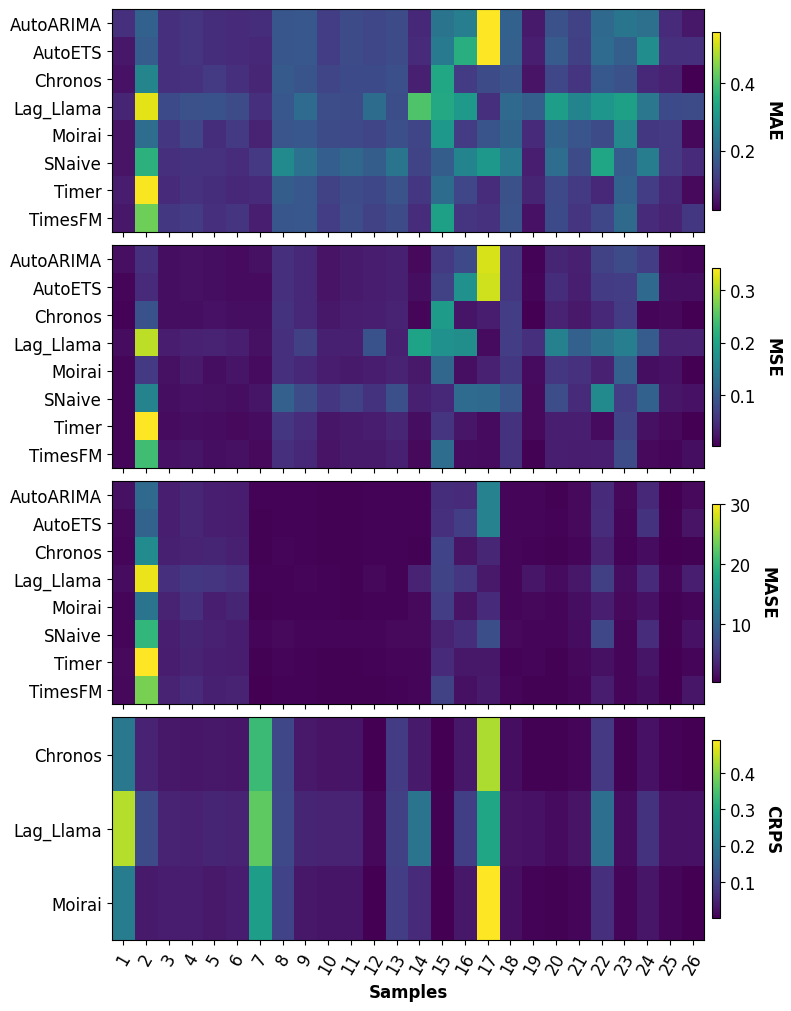

✅ PDF نهایی (یک صفحه، ۴ هیت‌مپ زیر هم) ساخته شد:
/content/drive/MyDrive/results/paper/figures/all_metrics_heatmaps_compact.pdf


In [ ]:
# @title

import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
from google.colab import drive

drive.mount('/content/drive')

excel_path = "/content/drive/MyDrive/results/paper/All_models_metrics_summary.xlsx"
df_metrics = pd.read_excel(excel_path)

metrics_main = ["mae_scaled", "mse_scaled","mase"]
metric_crps = "crps"

metric_display_name = {
    "mae_scaled": "MAE",
    "mse_scaled": "MSE",
    "crps": "CRPS",
    "mase": "MASE"
}

output_dir = "/content/drive/MyDrive/results/paper/figures"
os.makedirs(output_dir, exist_ok=True)

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

# فقط مدل‌هایی که CRPS دارند
crps_models = ["Chronos", "Moirai", "Lag_Llama"]
cell_width = 0.3   # ← این را اگر خواستی تغییر بده
# =====================================================
# 4) تابع رسم Heatmap یکپارچه و فشرده
# =====================================================
def plot_compact_heatmap(df, target_metric, allowed_models=None):
    df_use = df.copy()
    if allowed_models is not None:
        df_use = df_use[df_use["model"].isin(allowed_models)]

    heatmap_df = df_use.pivot(
        index="model",
        columns="dataset_id",
        values=target_metric
    ).sort_index(axis=1)

    heatmap_df = heatmap_df.dropna(how="all")
    if heatmap_df.empty:
        return None, None

    n_models = heatmap_df.shape[0]
    n_datasets = heatmap_df.shape[1]

    # کنترل عرض سلول‌ها

    fig_w = cell_width * n_datasets
    fig_h = max(2.2, 0.55 * n_models)



    fig, ax = plt.subplots(figsize=(fig_w, fig_h))

    im = ax.imshow(heatmap_df.values, cmap="viridis", aspect="auto")

    ax.set_xticks(np.arange(n_datasets))
    ax.set_yticks(np.arange(n_models))
    ax.set_xticklabels(heatmap_df.columns, rotation=90)
    ax.set_yticklabels(heatmap_df.index)

    ax.tick_params(axis="x", pad=1)
    ax.tick_params(axis="y", pad=1)
    ax.grid(False)

    # colorbar فشرده
    cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
    cbar.set_label(metric_display_name[target_metric], rotation=270, labelpad=10)

    plt.tight_layout(pad=0.2)

    return fig, ax

# =====================================================
# 5) ذخیره همه پلات‌ها در یک PDF
# =====================================================
# =====================================================
# 5) رسم همه متریک‌ها در یک صفحه (۴ هیت‌مپ زیر هم)
# =====================================================
pdf_path = f"{output_dir}/all_metrics_heatmaps_compact.pdf"

fig, axes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(cell_width * 26, 10),  # عرض ثابت، ارتفاع جمع‌شده
    constrained_layout=True
)

all_metrics = metrics_main + [metric_crps]

for idx, metric in enumerate(all_metrics):
    ax = axes[idx]

    # انتخاب مدل‌ها
    allowed = crps_models if metric == metric_crps else None

    df_use = df_metrics.copy()
    if allowed is not None:
        df_use = df_use[df_use["model"].isin(allowed)]

    heatmap_df = df_use.pivot(
        index="model",
        columns="dataset_id",
        values=metric
    ).sort_index(axis=1)

    heatmap_df = heatmap_df.dropna(how="all")

    im = ax.imshow(heatmap_df.values, cmap="viridis", aspect="auto")

    ax.set_yticks(np.arange(heatmap_df.shape[0]))
    ax.set_yticklabels(heatmap_df.index)

    ax.set_xticks(np.arange(heatmap_df.shape[1]))
    if idx == len(all_metrics) - 1:
        ax.set_xticklabels(heatmap_df.columns, rotation=60)
        ax.set_xlabel("Samples")
    else:
        ax.set_xticklabels([])


    ax.grid(False)

    # colorbar جدا برای هر سطر
    cbar = fig.colorbar(im, ax=ax, fraction=0.015, pad=0.01)
    cbar.set_label(metric_display_name[metric], rotation=270, labelpad=18)

# ذخیره فقط یک‌بار
with PdfPages(pdf_path) as pdf:
    pdf.savefig(fig, bbox_inches="tight")

plt.show()
plt.close(fig)

print("✅ PDF نهایی (یک صفحه، ۴ هیت‌مپ زیر هم) ساخته شد:")
print(pdf_path)



# Ranking HEATMAP

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


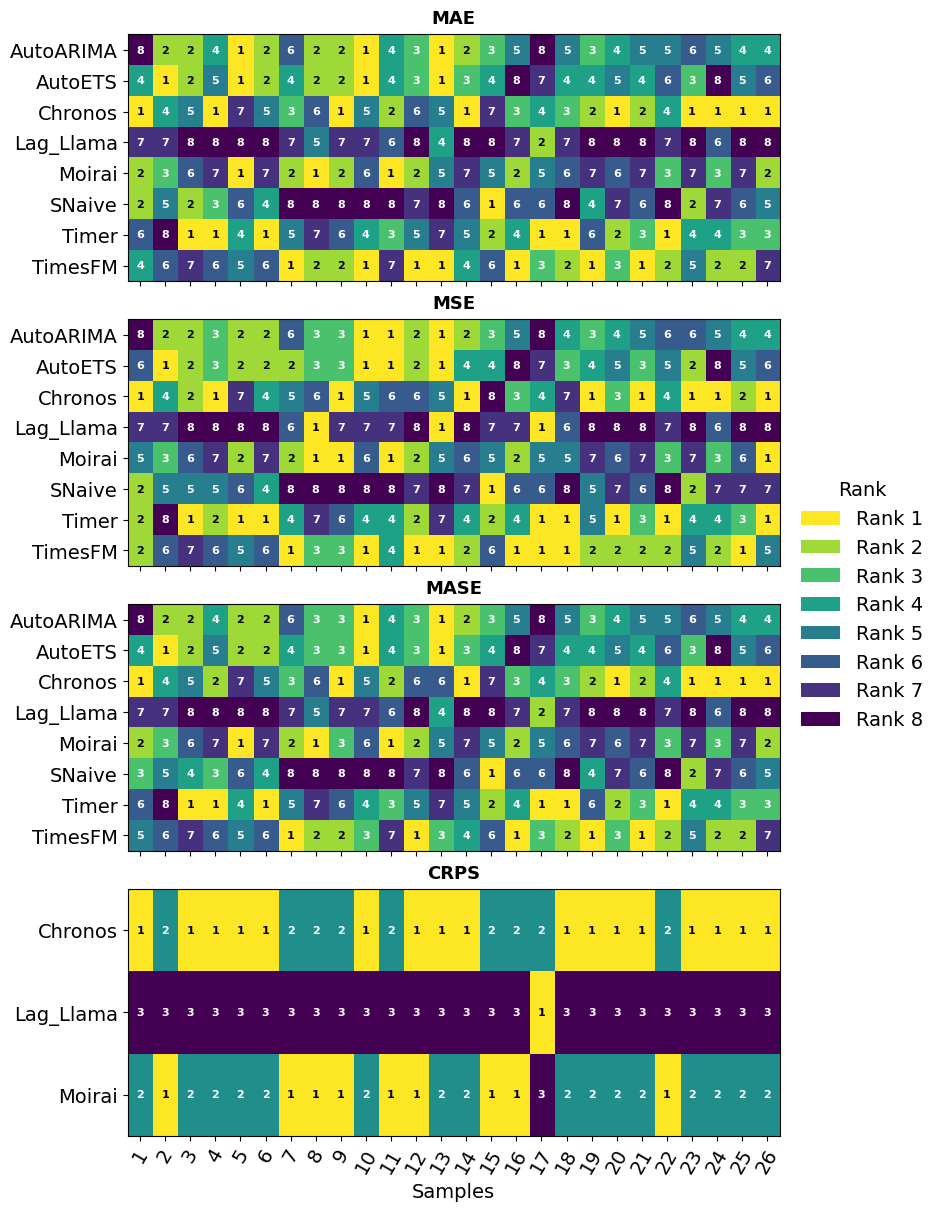

✅ PDF نهایی Rank Heatmap با یک Legend مشترک ساخته شد:
/content/drive/MyDrive/results/paper/figures/all_metrics_rank_heatmaps_compact.pdf


In [2]:
# @title
# =====================================================
# 0) کتابخانه‌ها
# =====================================================
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from google.colab import drive

# =====================================================
# 1) اتصال به Google Drive
# =====================================================
drive.mount('/content/drive')

# =====================================================
# 2) بارگذاری نتایج
# =====================================================
excel_path = "/content/drive/MyDrive/results/paper/All_models_metrics_summary.xlsx"
df_metrics = pd.read_excel(excel_path)

# =====================================================
# 3) تنظیمات
# =====================================================
metrics_main = ["mae_scaled",  "mse_scaled","mase"]
metric_crps = "crps"

metric_display_name = {
    "mae_scaled": "MAE",
    "mse_scaled": "MSE",
    "crps": "CRPS",
    "mase": "MASE"

}

output_dir = "/content/drive/MyDrive/results/paper/figures"
os.makedirs(output_dir, exist_ok=True)

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 14,
    "axes.labelsize": 14,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14
})

crps_models = ["Chronos", "Moirai", "Lag_Llama"]
cell_width = 0.3

# =====================================================
# 4) Rank Heatmaps – یک صفحه، ۴ subplot زیر هم
# =====================================================
pdf_path = f"{output_dir}/all_metrics_rank_heatmaps_compact.pdf"

fig, axes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(cell_width * 26, 12),
    constrained_layout=True
)

all_metrics = metrics_main + [metric_crps]

# برای ساخت Legend مشترک
global_legend_handles = None

for idx, metric in enumerate(all_metrics):
    ax = axes[idx]

    allowed = crps_models if metric == metric_crps else None

    df_use = df_metrics.copy()
    if allowed is not None:
        df_use = df_use[df_use["model"].isin(allowed)]

    value_df = df_use.pivot(
        index="model",
        columns="dataset_id",
        values=metric
    ).sort_index(axis=1)

    value_df = value_df.dropna(how="all")

    # ---------- Rank ----------
    rank_df = value_df.rank(
        axis=0,
        method="min",
        ascending=True
    )

    n_ranks = int(rank_df.max().max())

    # ---------- colormap گسسته ----------
    base_cmap = plt.get_cmap("viridis_r")
    colors = base_cmap(np.linspace(0, 1, n_ranks))
    cmap = ListedColormap(colors)
    norm = BoundaryNorm(
        np.arange(0.5, n_ranks + 1.5),
        cmap.N
    )

    im = ax.imshow(
        rank_df.values,
        cmap=cmap,
        norm=norm,
        aspect="auto"
    )

    # =================================================
    # عنوان Metric بالای هر subplot
    # =================================================
    ax.set_title(
        metric_display_name[metric],
        fontsize=13,
        fontweight="bold",
        pad=8
    )

    # y-axis
    ax.set_yticks(np.arange(rank_df.shape[0]))
    ax.set_yticklabels(rank_df.index)

    # x-axis
    ax.set_xticks(np.arange(rank_df.shape[1]))

    if idx == len(all_metrics) - 1:
        ax.set_xticklabels(
            rank_df.columns,
            rotation=60
        )
        ax.set_xlabel("Samples")
    else:
        ax.set_xticklabels([])

    ax.grid(False)

    # =================================================
    # عدد Rank داخل سلول
    # =================================================
    for i in range(rank_df.shape[0]):
        for j in range(rank_df.shape[1]):
            r = int(rank_df.values[i, j])

            rgba = cmap(norm(r))
            luminance = (
                0.299 * rgba[0]
                + 0.587 * rgba[1]
                + 0.114 * rgba[2]
            )

            txt_color = "black" if luminance > 0.6 else "white"

            ax.text(
                j,
                i,
                f"{r}",
                ha="center",
                va="center",
                fontsize=8,
                fontweight="bold",
                color=txt_color
            )

    # =================================================
    # فقط یک Legend مشترک برای کل Figure
    # =================================================
    # در اولین subplot، Legend را برای کل figure آماده می‌کنیم
    if idx == 0:
        global_legend_handles = [
            Patch(
                facecolor=cmap(norm(r)),
                edgecolor="none",
                label=f"Rank {r}"
            )
            for r in range(1, n_ranks + 1)
        ]

# =====================================================
# Legend مشترک Figure
# =====================================================
if global_legend_handles is not None:
    fig.legend(
        handles=global_legend_handles,
        loc="center left",
        bbox_to_anchor=(1.01, 0.5),
        frameon=False,
        borderaxespad=0.0,
        title="Rank"
    )

# =====================================================
# ذخیره
# =====================================================
with PdfPages(pdf_path) as pdf:
    pdf.savefig(
        fig,
        bbox_inches="tight"
    )

plt.show()
plt.close(fig)

print("✅ PDF نهایی Rank Heatmap با یک Legend مشترک ساخته شد:")
print(pdf_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


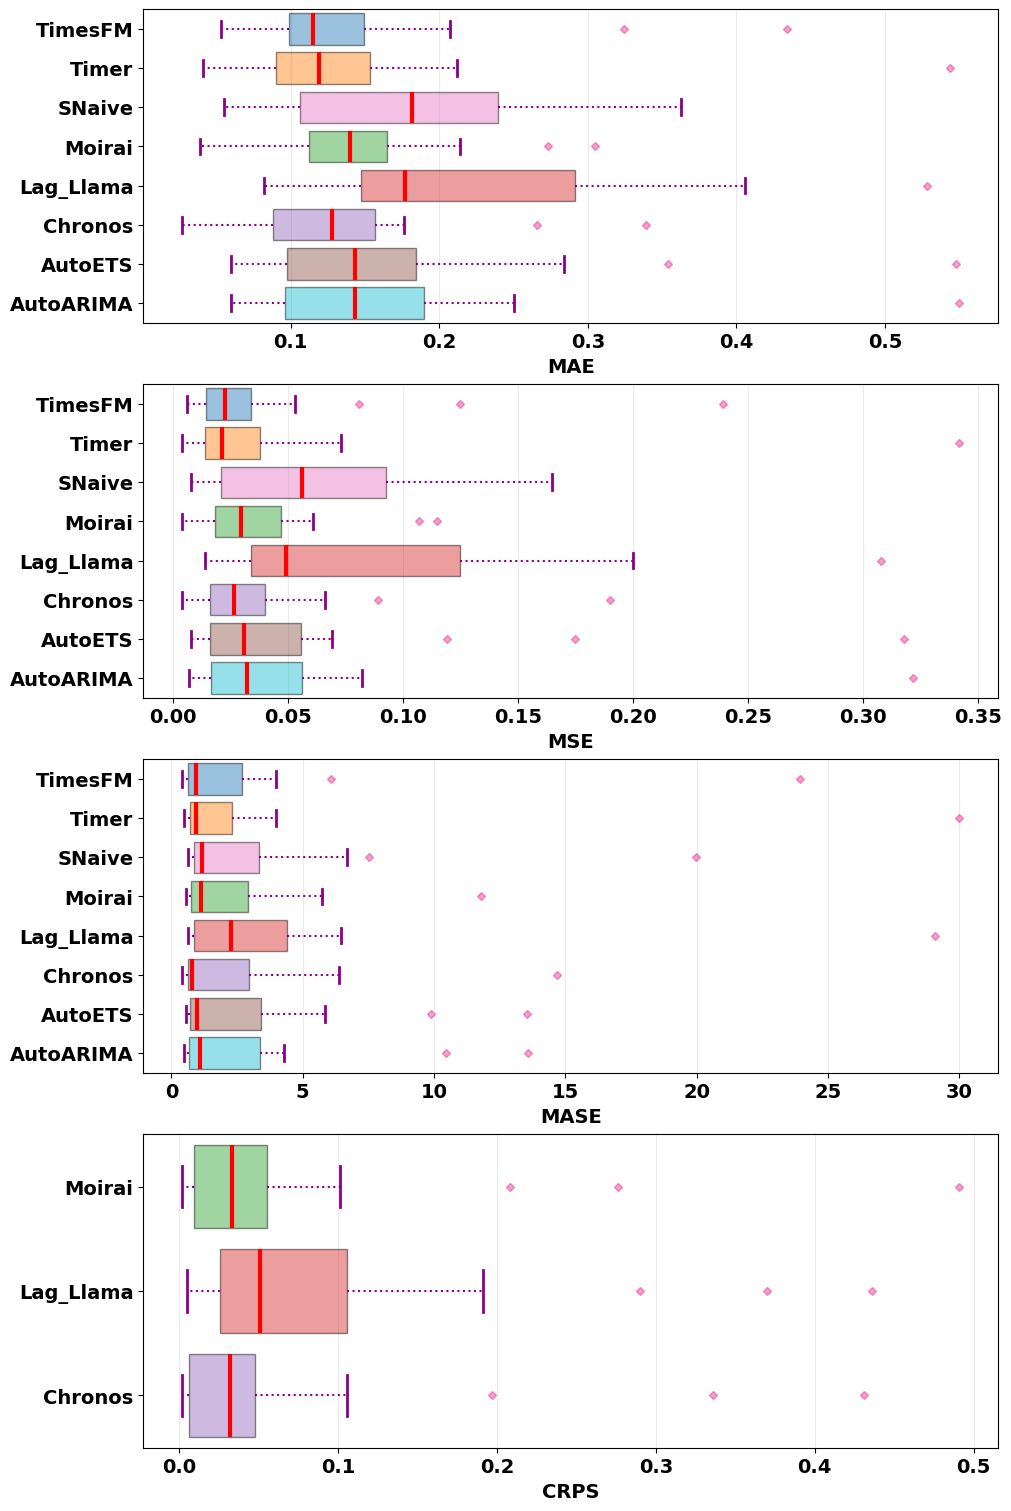

✅ PDF نهایی (۴ boxplot در یک صفحه) با فونت Bold ساخته شد:
/content/drive/MyDrive/results/paper/figures/all_metrics_boxplots_one_page.pdf


In [4]:
# @title
# =====================================================
# 0) کتابخانه‌ها
# =====================================================
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from google.colab import drive

# =====================================================
# 1) اتصال به Google Drive
# =====================================================
drive.mount('/content/drive')

# =====================================================
# 2) بارگذاری داده‌ها
# =====================================================
excel_path = "/content/drive/MyDrive/results/paper/All_models_metrics_summary.xlsx"
df_metrics = pd.read_excel(excel_path)

# =====================================================
# 3) تنظیمات
# =====================================================
metrics_main = ["mae_scaled", "mse_scaled","mase"]
metric_crps = "crps"

metric_display_name = {
    "mae_scaled": "MAE",
    "mse_scaled": "MSE",
    "crps": "CRPS",
    "mase": "MASE"
}

crps_models = ["Chronos", "Moirai", "Lag_Llama"]

# =====================================================
# تنظیمات فونت – همه نوشته‌ها Bold
# =====================================================
plt.rcParams.update({
    "font.size": 14,
    "font.weight": "bold",
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 14,
    "axes.labelweight": "bold",
    "xtick.labelsize": 14,
    "ytick.labelsize": 14
})

# =====================================================
# 4) تابع رسم Boxplot روی یک axis مشخص
# =====================================================
def plot_styled_boxplot_on_ax(ax, df, metric, allowed_models=None):

    df_use = df.copy()

    if allowed_models is not None:
        df_use = df_use[df_use["model"].isin(allowed_models)]

    models = sorted(df_use["model"].unique())

    data = [
        df_use.loc[
            df_use["model"] == m,
            metric
        ].dropna().values
        for m in models
    ]

    bp = ax.boxplot(
        data,
        patch_artist=True,
        notch=False,
        vert=False,
        widths=0.8

    )



    # =================================================
    # رنگ Boxها
    # =================================================
    model_colors = {
        "TimesFM":   "#1F77B4",  # Blue
        "Timer":     "#FF7F0E",  # Orange
        "Moirai":    "#2CA02C",  # Green
        "Lag_Llama": "#D62728",  # Red
        "Chronos":   "#9467BD",  # Purple
        "AutoETS":       "#8C564B",  # Brown
        "SNaive":        "#E377C2",  # Pink
        "AutoARIMA":     "#17BECF"   # Cyan
    }

    for patch, model in zip(bp['boxes'], models):
        color = model_colors.get(model, "#7F7F7F")
        patch.set_facecolor(color)
        patch.set_alpha(0.45)

    # =================================================
    # Whiskers
    # =================================================
    for whisker in bp['whiskers']:
        whisker.set(
            color='#8B008B',
            linewidth=1.5,
            linestyle=':'
        )

    # =================================================
    # Caps
    # =================================================
    for cap in bp['caps']:
        cap.set(
            color='#8B008B',
            linewidth=2
        )

    # =================================================
    # Median
    # =================================================
    for median in bp['medians']:
        median.set(
            color='red',
            linewidth=3
        )

    # =================================================
    # Outliers
    # =================================================
    for flier in bp['fliers']:
        flier.set(
            marker='D',
            markerfacecolor='#e7298a',
            markeredgecolor='#e7298a',
            alpha=0.45,
            markersize=4
        )

    # =================================================
    # نام مدل‌ها روی محور Y
    # =================================================
    ax.set_yticklabels(
        models,
        fontweight='bold',
        fontsize=14
    )

    # =================================================
    # Label محور X
    # =================================================
    ax.set_xlabel(
        metric_display_name[metric],
        fontsize=14,
        fontweight='bold'
    )

    # =================================================
    # Bold کردن Tickهای محور X
    # =================================================
    for label in ax.get_xticklabels():
        label.set_fontweight('bold')
        label.set_fontsize(14)

    # =================================================
    # Bold کردن Tickهای محور Y
    # =================================================
    for label in ax.get_yticklabels():
        label.set_fontweight('bold')
        label.set_fontsize(14)

    # =================================================
    # Grid
    # =================================================
    ax.grid(
        True,
        axis='x',
        alpha=0.25
    )

# =====================================================
# 5) رسم همه Boxplotها در یک صفحه و ذخیره PDF
# =====================================================
output_path = "/content/drive/MyDrive/results/paper/figures/all_metrics_boxplots_one_page.pdf"

fig, axes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(10,15),
    constrained_layout=True
)

all_metrics = metrics_main + [metric_crps]

for idx, metric in enumerate(all_metrics):

    allowed = (
        crps_models
        if metric == metric_crps
        else None
    )

    plot_styled_boxplot_on_ax(
        axes[idx],
        df_metrics,
        metric,
        allowed_models=allowed
    )

# =====================================================
# ذخیره PDF
# =====================================================
with PdfPages(output_path) as pdf:
    pdf.savefig(
        fig,
        bbox_inches="tight"
    )

plt.show()
plt.close(fig)

print("✅ PDF نهایی (۴ boxplot در یک صفحه) با فونت Bold ساخته شد:")
print(output_path)

In [5]:
import numpy as np
import pandas as pd

# =====================================================
# 6) استخراج آمار Boxplot برای تمام مدل‌ها و معیارها
# =====================================================

boxplot_stats = []

for metric in all_metrics:

    allowed_models = (
        crps_models if metric == "crps" else None
    )

    df_use = df_metrics.copy()

    if allowed_models is not None:
        df_use = df_use[
            df_use["model"].isin(allowed_models)
        ]

    for model in sorted(df_use["model"].unique()):

        values = df_use.loc[
            df_use["model"] == model, metric
        ].dropna().to_numpy(dtype=float)

        if len(values) == 0:
            continue

        # Quartiles
        q1 = np.percentile(values, 25)
        median = np.median(values)
        q3 = np.percentile(values, 75)

        # Interquartile Range
        iqr = q3 - q1

        # Outlier thresholds (1.5 × IQR)
        lower_fence = q1 - 1.5 * iqr
        upper_fence = q3 + 1.5 * iqr

        # Outliers
        outliers = values[
            (values < lower_fence) |
            (values > upper_fence)
        ]

        # Whiskers: actual observations within fences
        non_outliers = values[
            (values >= lower_fence) &
            (values <= upper_fence)
        ]

        boxplot_stats.append({
            "Metric": metric_display_name[metric],
            "Model": model,
            "N": len(values),
            "Mean": np.mean(values),
            "Median": median,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "Min": np.min(values),
            "Max": np.max(values),
            "Range": np.max(values) - np.min(values),
            "Lower Whisker": np.min(non_outliers),
            "Upper Whisker": np.max(non_outliers),
            "Number of Outliers": len(outliers),
            "Outlier Values": ", ".join(
                f"{v:.6f}" for v in sorted(outliers)
            )
        })

# =====================================================
# 7) ذخیره خروجی Excel
# =====================================================

df_boxplot_stats = pd.DataFrame(boxplot_stats)

stats_output_path = (
    "/content/drive/MyDrive/results/paper/"
    "boxplot_statistics.xlsx"
)

df_boxplot_stats.to_excel(
    stats_output_path,
    index=False
)

print("Boxplot statistics saved:")
print(stats_output_path)

display(df_boxplot_stats.round(4))

Boxplot statistics saved:
/content/drive/MyDrive/results/paper/boxplot_statistics.xlsx


,Metric,Model,N,Mean,Median,Q1,Q3,IQR,Min,Max,Range,Lower Whisker,Upper Whisker,Number of Outliers,Outlier Values
0,MAE,AutoARIMA,26,0.1589,0.1430,0.0962,0.1900,0.0938,0.060,0.550,0.490,0.060,0.250,1,0.550000
1,MAE,AutoETS,26,0.1648,0.1430,0.0972,0.1842,0.0870,0.060,0.548,0.488,0.060,0.284,2,"0.354000, 0.548000"
2,MAE,Chronos,26,0.1303,0.1280,0.0883,0.1565,0.0682,0.027,0.339,0.312,0.027,0.176,2,"0.266000, 0.339000"
3,MAE,Lag_Llama,26,0.2166,0.1770,0.1475,0.2912,0.1438,0.082,0.528,0.446,0.082,0.406,1,0.528000
4,MAE,Moirai,26,0.1453,0.1400,0.1122,0.1650,0.0528,0.039,0.305,0.266,0.039,0.214,2,"0.273000, 0.305000"
5,MAE,SNaive,26,0.1826,0.1815,0.1065,0.2392,0.1327,0.055,0.363,0.308,0.055,0.363,0,
6,MAE,Timer,26,0.1377,0.1190,0.0900,0.1535,0.0635,0.041,0.544,0.503,0.041,0.212,1,0.544000
7,MAE,TimesFM,26,0.1385,0.1150,0.0990,0.1495,0.0505,0.053,0.434,0.381,0.053,0.207,2,"0.324000, 0.434000"
8,MSE,AutoARIMA,26,0.0466,0.0320,0.0165,0.0562,0.0398,0.007,0.322,0.315,0.007,0.082,1,0.322000
9,MSE,AutoETS,26,0.0518,0.0310,0.0160,0.0555,0.0395,0.008,0.318,0.310,0.008,0.069,3,"0.119000, 0.175000, 0.318000"


# BEST MODEL

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
🏆 Best model for mae_scaled: Chronos
🏆 Best model for mse_scaled: TimesFM
🏆 Best model for mase: Chronos
🏆 Best model for crps: Chronos


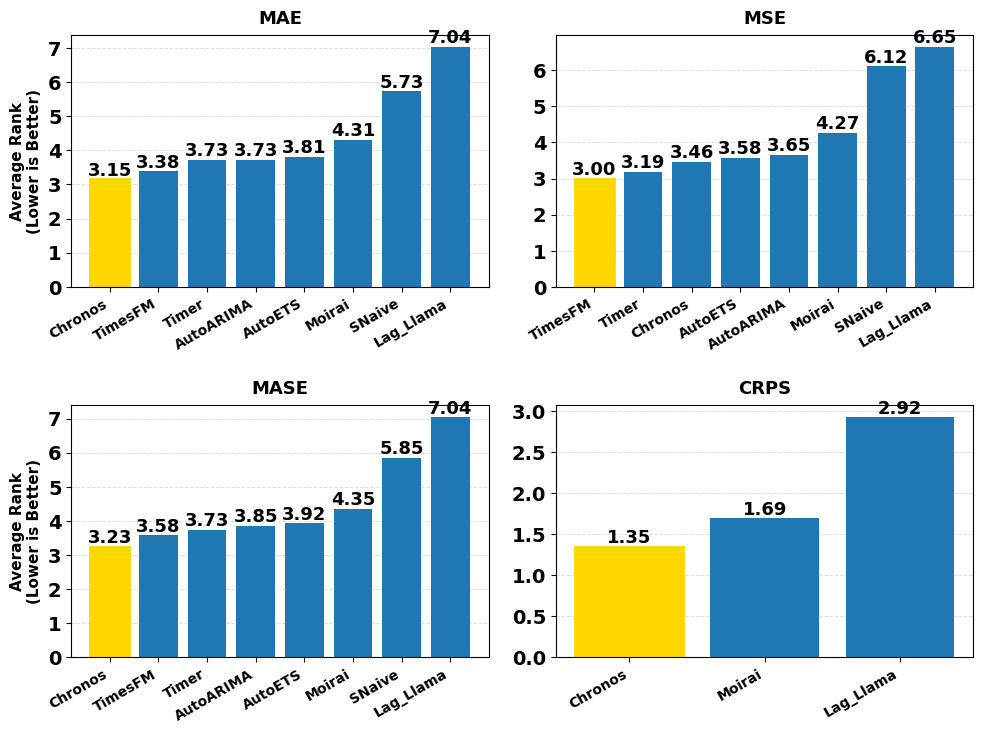

✅ Article-ready PDF saved:
/content/drive/MyDrive/results/paper/best_for_metric/average_rank_2x2_article.pdf


In [ ]:
# @title
import os
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

# ----------------------------------
# اتصال به Drive
# ----------------------------------
drive.mount('/content/drive')

# ----------------------------------
# بارگذاری نتایج
# ----------------------------------
df = pd.read_excel(
    "/content/drive/MyDrive/results/paper/All_models_metrics_summary.xlsx"
)

# ----------------------------------
# متریک‌ها
# ----------------------------------
metrics = [
    "mae_scaled",
    "mse_scaled",
    "mase",
    "crps"
]

metric_display_name = {
    "mae_scaled": "MAE",
    "mse_scaled": "MSE",
    "crps": "CRPS",
    "mase": "MASE"
}

# ----------------------------------
# تنظیمات فونت مناسب مقاله
# ----------------------------------
plt.rcParams.update({
    "font.size": 11,
    "font.family": "DejaVu Sans",

    "axes.titlesize": 13,
    "axes.titleweight": "bold",

    "axes.labelsize": 11,
    "axes.labelweight": "bold",

    "xtick.labelsize": 10,
    "ytick.labelsize": 10,

    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

# ----------------------------------
# تنظیم Grid (3×2) برای پشتیبانی از 5 متریک
# ----------------------------------
n_rows, n_cols = 2, 2

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(10,7.5),
    sharey=False
)

axes = axes.flatten()

# ----------------------------------
# پردازش هر متریک
# ----------------------------------
for idx, target_metric in enumerate(metrics):

    # Pivot: Model × Dataset
    value_df = df.pivot(
        index="model",
        columns="file_name",
        values=target_metric
    )

    # Rank (1 = بهترین)
    rank_df = value_df.rank(
        axis=0,
        ascending=True,
        method="min"
    )

    # Average Rank
    avg_rank = rank_df.mean(axis=1).sort_values()

    best_model = avg_rank.index[0]

    ax = axes[idx]

    # ----------------------------------
    # رسم میله‌ها
    # ----------------------------------
    bars = ax.bar(
        avg_rank.index,
        avg_rank.values
    )

    # ----------------------------------
    # عنوان متریک
    # ----------------------------------
    ax.set_title(
        metric_display_name[target_metric],
        fontsize=13,
        fontweight="bold",
        pad=8
    )

    # ----------------------------------
    # Grid
    # ----------------------------------
    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.7,
        alpha=0.4
    )

    # Grid پشت ستون‌ها
    ax.set_axisbelow(True)

    # ----------------------------------
    # برچسب محور Y فقط ستون سمت چپ
    # ----------------------------------
    if idx % n_cols == 0:
        ax.set_ylabel(
            "Average Rank\n(Lower is Better)",
            fontsize=11,
            fontweight="bold"
        )
    else:
        ax.set_ylabel("")

    # ----------------------------------
    # چرخاندن نام مدل‌ها روی محور X
    # ----------------------------------
    ax.tick_params(
        axis="x",
        labelrotation=30
    )

    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")
        label.set_fontsize(10)
        label.set_fontweight("bold")

    # ----------------------------------
    # Bold کردن اعداد محور Y
    # ----------------------------------
    for label in ax.get_yticklabels():
        label.set_fontsize(14)
        label.set_fontweight("bold")

    # ----------------------------------
    # مقدار روی ستون‌ها
    # ----------------------------------
    for i, v in enumerate(avg_rank.values):
        if not pd.isna(v):
            ax.text(
                i,
                v,
                f"{v:.2f}",
                ha="center",
                va="bottom",
                fontsize=13,
                fontweight="bold"
            )

    # ----------------------------------
    # هایلایت بهترین مدل
    # ----------------------------------
    for bar, model in zip(bars, avg_rank.index):
        if model == best_model:
            bar.set_edgecolor("black")
            bar.set_color("#FFD700")
            bar.set_linewidth(2)

    # ----------------------------------
    # ضخیم‌تر کردن کادر نمودار
    # ----------------------------------
    for spine in ax.spines.values():
        spine.set_linewidth(0.8)

    print(
        f"🏆 Best model for {target_metric}: {best_model}"
    )

# مخفی کردن ساب‌پلات ششم (آخرین ساب‌پلات خالی)
if len(axes) > len(metrics):
    for empty_idx in range(len(metrics), len(axes)):
        fig.delaxes(axes[empty_idx])

# ----------------------------------
# تنظیم فاصله‌ها
# ----------------------------------
plt.tight_layout(
    pad=1.2,
    w_pad=1.5,
    h_pad=1.8
)

# ----------------------------------
# ذخیره PDF با کیفیت مناسب مقاله
# ----------------------------------
output_dir = "/content/drive/MyDrive/results/paper/best_for_metric"
os.makedirs(output_dir, exist_ok=True)

pdf_path = f"{output_dir}/average_rank_2x2_article.pdf"

plt.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight"
)

plt.show()
plt.close()

print(f"✅ Article-ready PDF saved:")
print(pdf_path)

# scatter plots

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
mae_scaled   | TimesFM    | n=26 | Slope=0.002 | Pearson r=0.085 | Pearson p=0.6783 | Spearman rho=-0.301 | Spearman p=0.1357
mae_scaled   | Timer      | n=26 | Slope=0.002 | Pearson r=0.085 | Pearson p=0.6809 | Spearman rho=-0.401 | Spearman p=0.0424
mae_scaled   | Moirai     | n=26 | Slope=-0.004 | Pearson r=-0.278 | Pearson p=0.1695 | Spearman rho=-0.372 | Spearman p=0.0616
mae_scaled   | Lag_Llama  | n=26 | Slope=0.001 | Pearson r=0.057 | Pearson p=0.7839 | Spearman rho=-0.088 | Spearman p=0.6706
mae_scaled   | Chronos    | n=26 | Slope=-0.001 | Pearson r=-0.063 | Pearson p=0.7607 | Spearman rho=-0.287 | Spearman p=0.1547
mse_scaled   | TimesFM    | n=26 | Slope=0.002 | Pearson r=0.149 | Pearson p=0.4677 | Spearman rho=-0.275 | Spearman p=0.1746
mse_scaled   | Timer      | n=26 | Slope=0.003 | Pearson r=0.178 | Pearson p=0.3847 | Spearman rho=-0.411 | Spe

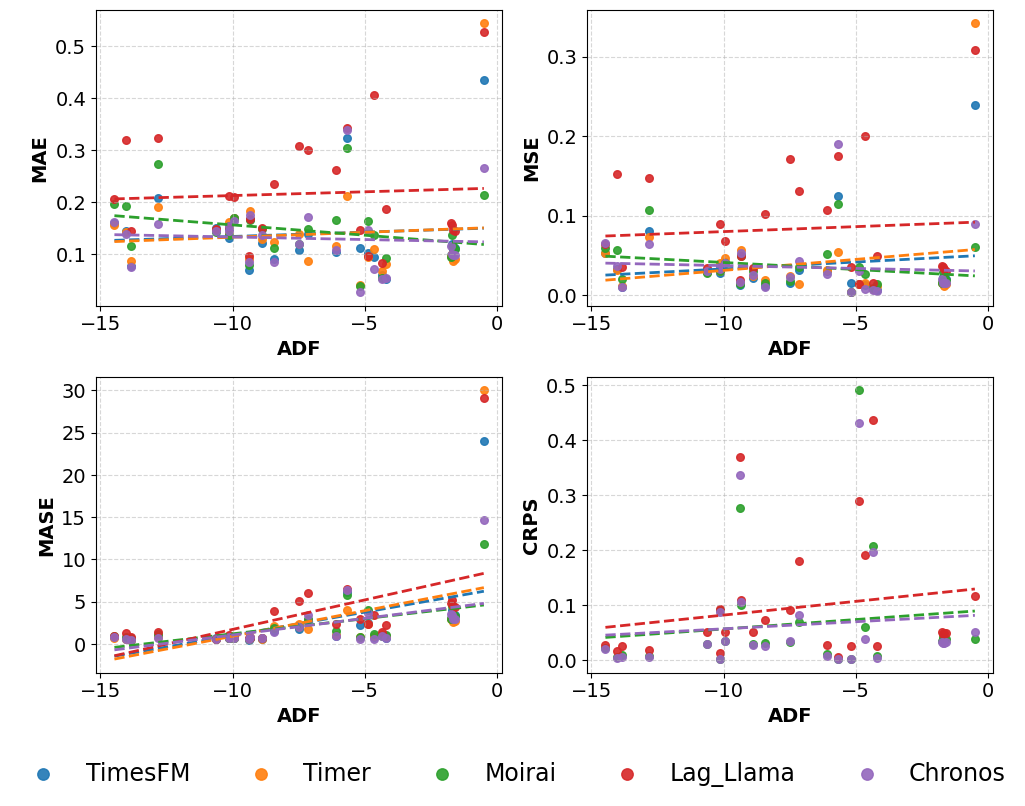



CORRELATION RESULTS
    Metric     Model  N   Slope  Pearson_r  Pearson_p  Spearman_rho  Spearman_p
mae_scaled   TimesFM 26  0.0017     0.0854     0.6783       -0.3006      0.1357
mae_scaled     Timer 26  0.0019     0.0847     0.6809       -0.4008      0.0424
mae_scaled    Moirai 26 -0.0040    -0.2778     0.1695       -0.3715      0.0616
mae_scaled Lag_Llama 26  0.0014     0.0565     0.7839       -0.0876      0.6706
mae_scaled   Chronos 26 -0.0010    -0.0628     0.7607       -0.2873      0.1547
mse_scaled   TimesFM 26  0.0017     0.1489     0.4677       -0.2746      0.1746
mse_scaled     Timer 26  0.0028     0.1779     0.3847       -0.4107      0.0372
mse_scaled    Moirai 26 -0.0018    -0.2729     0.1774       -0.3356      0.0938
mse_scaled Lag_Llama 26  0.0012     0.0714     0.7289       -0.1109      0.5895
mse_scaled   Chronos 26 -0.0007    -0.0769     0.7087       -0.3908      0.0484
      mase   TimesFM 26  0.5495     0.4962     0.0099        0.7361      0.0000
      mase     Tim

In [ ]:
# @title
# =====================================================
# 0) کتابخانه‌ها
# =====================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr, spearmanr
from google.colab import drive


# =====================================================
# 1) اتصال به Google Drive
# =====================================================

drive.mount('/content/drive')


# =====================================================
# 2) بارگذاری داده
# =====================================================

input_path = "/content/drive/MyDrive/results/paper/All_models_metrics_summary.xlsx"

df = pd.read_excel(input_path)


# =====================================================
# 3) تنظیمات
# =====================================================

all_models = ["TimesFM", "Timer", "Moirai", "Lag_Llama", "Chronos"]
metrics = ["mae_scaled", "mse_scaled","mase", "crps"]

metric_ylabel = {
    "mae_scaled": "MAE",
    "mse_scaled": "MSE",
    "mase": "MASE",
    "crps": "CRPS"
}

# رنگ هر مدل
colors = {
    "TimesFM": "#1f77b4",
    "Timer": "#ff7f0e",
    "Moirai": "#2ca02c",
    "Lag_Llama": "#d62728",
    "Chronos": "#9467bd",
}


# =====================================================
# 4) تنظیم فونت‌ها
# =====================================================

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.labelsize": 14,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 17
})


# =====================================================
# 5) لیست برای ذخیره نتایج آماری
# =====================================================

correlation_results = []


# =====================================================
# 6) شکل 2×2
# =====================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10, 8)
)

axes = axes.flatten()


# =====================================================
# 7) رسم نمودارها و محاسبه correlations
# =====================================================

for i, target_metric in enumerate(metrics):

    ax = axes[i]

    # -------------------------------------------------
    # فقط سه مدل برای CRPS
    # -------------------------------------------------

    if target_metric == "crps":
        models = [
            "Moirai",
            "Lag_Llama",
            "Chronos"
        ]
    else:
        models = all_models


    # -------------------------------------------------
    # پردازش هر مدل
    # -------------------------------------------------

    for model_name in models:

        df_model = df[
            df["model"] == model_name
        ].copy()

        # حذف missing values
        df_model = df_model.dropna(
            subset=["ADF", target_metric]
        )

        # مرتب‌سازی بر اساس ADF
        df_model = df_model.sort_values(
            by="ADF"
        )


        # حداقل تعداد داده
        if len(df_model) < 3:
            print(
                f"WARNING: Not enough data for "
                f"{target_metric} - {model_name}"
            )
            continue


        # -------------------------------------------------
        # داده‌های X و Y
        # -------------------------------------------------

        x = df_model["ADF"].values
        y = df_model[target_metric].values


        # تعداد واقعی نمونه‌ها
        n = len(x)


        # -------------------------------------------------
        # Linear Regression
        # -------------------------------------------------

        slope, intercept = np.polyfit(
            x,
            y,
            1
        )

        trend = (
            slope * x
            + intercept
        )


        # -------------------------------------------------
        # Pearson correlation + p-value
        # -------------------------------------------------

        pearson_r, pearson_p = pearsonr(
            x,
            y
        )


        # -------------------------------------------------
        # Spearman correlation + p-value
        # -------------------------------------------------

        spearman_rho, spearman_p = spearmanr(
            x,
            y
        )


        # -------------------------------------------------
        # چاپ نتایج در Colab
        # -------------------------------------------------

        print(
            f"{target_metric:12s} | "
            f"{model_name:10s} | "
            f"n={n:2d} | "
            f"Slope={slope:.3f} | "
            f"Pearson r={pearson_r:.3f} | "
            f"Pearson p={pearson_p:.4f} | "
            f"Spearman rho={spearman_rho:.3f} | "
            f"Spearman p={spearman_p:.4f}"
        )


        # -------------------------------------------------
        # ذخیره نتایج برای Excel
        # -------------------------------------------------

        correlation_results.append({
            "Metric": target_metric,
            "Model": model_name,
            "N": n,
            "Slope": slope,

            "Pearson_r": pearson_r,
            "Pearson_p": pearson_p,

            "Spearman_rho": spearman_rho,
            "Spearman_p": spearman_p
        })


        # -------------------------------------------------
        # Scatter plot
        # -------------------------------------------------

        ax.scatter(
            x,
            y,
            s=30,
            color=colors[model_name],
            alpha=0.9,
            label=model_name
        )


        # -------------------------------------------------
        # Trend line
        # -------------------------------------------------

        ax.plot(
            x,
            trend,
            color=colors[model_name],
            linestyle="--",
            linewidth=2
        )


    # =================================================
    # تنظیمات subplot
    # =================================================

    ax.set_xlabel(
        "ADF",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_ylabel(
        metric_ylabel[target_metric],
        fontsize=14,
        fontweight="bold"
    )

    ax.tick_params(
        axis="both",
        labelsize=14
    )

    ax.grid(
        True,
        linestyle="--",
        alpha=0.5
    )


# =====================================================
# 8) Legend مشترک
# =====================================================

handles, labels = (
    axes[0].get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=5,
    fontsize=17,
    frameon=False,
    markerscale=1.5
)


# =====================================================
# 9) تنظیم فاصله‌ها
# =====================================================

plt.tight_layout(
    rect=[0, 0.06, 1, 1]
)


# =====================================================
# 10) ذخیره شکل PDF
# =====================================================

pdf_path = (
    "/content/drive/MyDrive/results/paper/"
    "figures/ADF_vs_AllMetrics_2x2.pdf"
)

plt.savefig(
    pdf_path,
    format="pdf",
    dpi=600,
    bbox_inches="tight"
)


# =====================================================
# 11) نمایش شکل
# =====================================================

plt.show()


# =====================================================
# 12) تبدیل نتایج آماری به DataFrame
# =====================================================

correlation_df = pd.DataFrame(
    correlation_results
)


# =====================================================
# 13) نمایش جدول نتایج
# =====================================================

print("\n")
print("=" * 100)
print("CORRELATION RESULTS")
print("=" * 100)

print(
    correlation_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# =====================================================
# 14) ذخیره نتایج آماری در Excel
# =====================================================

excel_path = (
    "/content/drive/MyDrive/results/paper/"
    "ADF_correlation_statistics.xlsx"
)

correlation_df.to_excel(
    excel_path,
    index=False
)


# =====================================================
# 15) پیام نهایی
# =====================================================

print("\n")
print("=" * 100)
print("FILES SAVED SUCCESSFULLY")
print("=" * 100)

print(f"Figure:")
print(pdf_path)

print("\nCorrelation statistics:")
print(excel_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
mae_scaled   | TimesFM    | n=26 | Slope=0.006 | Pearson r=0.073 | Pearson p=0.7232 | Spearman rho=-0.306 | Spearman p=0.1279
mae_scaled   | Timer      | n=26 | Slope=0.006 | Pearson r=0.069 | Pearson p=0.7361 | Spearman rho=-0.331 | Spearman p=0.0987
mae_scaled   | Moirai     | n=26 | Slope=0.002 | Pearson r=0.032 | Pearson p=0.8777 | Spearman rho=-0.230 | Spearman p=0.2589
mae_scaled   | Lag_Llama  | n=26 | Slope=0.022 | Pearson r=0.221 | Pearson p=0.2778 | Spearman rho=0.067 | Spearman p=0.7454
mae_scaled   | Chronos    | n=26 | Slope=-0.013 | Pearson r=-0.209 | Pearson p=0.3047 | Spearman rho=-0.427 | Spearman p=0.0295
mse_scaled   | TimesFM    | n=26 | Slope=0.009 | Pearson r=0.199 | Pearson p=0.3291 | Spearman rho=-0.209 | Spearman p=0.3046
mse_scaled   | Timer      | n=26 | Slope=0.011 | Pearson r=0.184 | Pearson p=0.3686 | Spearman rho=-0.269 | Spearm

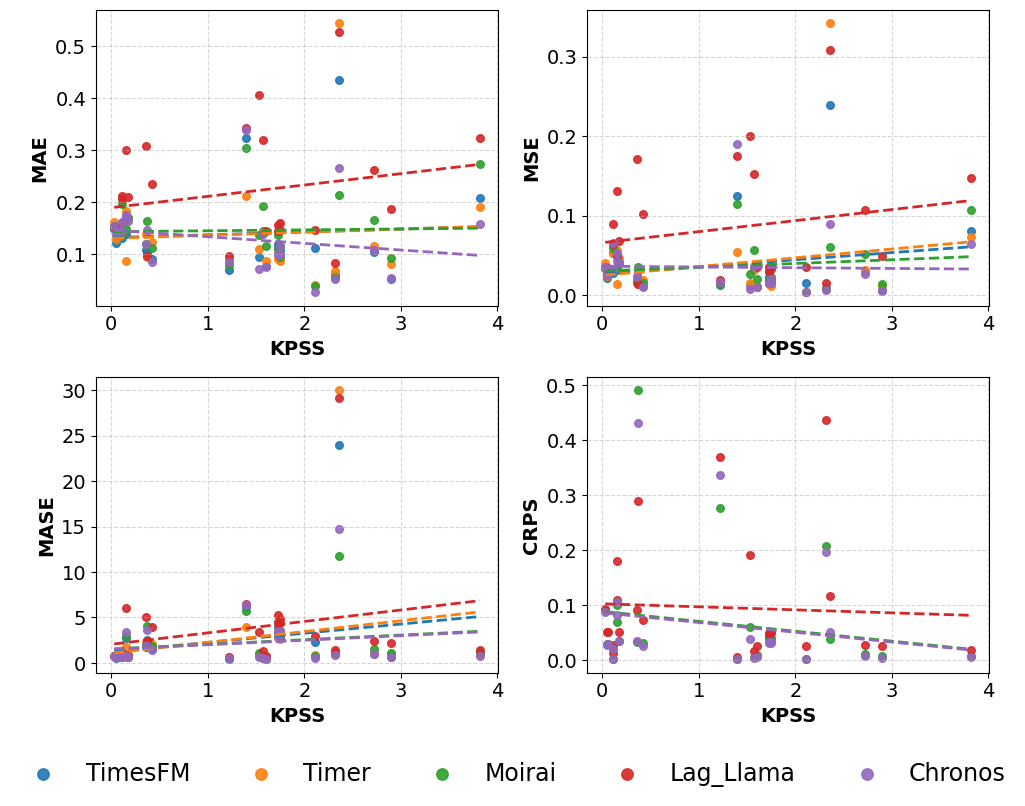



CORRELATION RESULTS
    Metric     Model  N   Slope  Pearson_r  Pearson_p  Spearman_rho  Spearman_p
mae_scaled   TimesFM 26  0.0055     0.0730     0.7232       -0.3064      0.1279
mae_scaled     Timer 26  0.0060     0.0694     0.7361       -0.3309      0.0987
mae_scaled    Moirai 26  0.0018     0.0317     0.8777       -0.2297      0.2589
mae_scaled Lag_Llama 26  0.0218     0.2210     0.2778        0.0669      0.7454
mae_scaled   Chronos 26 -0.0128    -0.2094     0.3047       -0.4273      0.0295
mse_scaled   TimesFM 26  0.0090     0.1993     0.3291       -0.2094      0.3046
mse_scaled     Timer 26  0.0110     0.1839     0.3686       -0.2686      0.1847
mse_scaled    Moirai 26  0.0047     0.1880     0.3576       -0.1876      0.3588
mse_scaled Lag_Llama 26  0.0139     0.2055     0.3138        0.1126      0.5841
mse_scaled   Chronos 26 -0.0009    -0.0262     0.8991       -0.3523      0.0775
      mase   TimesFM 26  1.0113     0.2358     0.2461        0.3657      0.0662
      mase     Tim

In [ ]:
# @title
# =====================================================
# 0) کتابخانه‌ها
# =====================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr, spearmanr
from google.colab import drive


# =====================================================
# 1) اتصال به Google Drive
# =====================================================

drive.mount('/content/drive')


# =====================================================
# 2) بارگذاری داده
# =====================================================

input_path = "/content/drive/MyDrive/results/paper/All_models_metrics_summary.xlsx"

df = pd.read_excel(input_path)


# =====================================================
# 3) تنظیمات
# =====================================================

all_models = ["TimesFM", "Timer", "Moirai", "Lag_Llama", "Chronos"]
metrics = ["mae_scaled", "mse_scaled","mase", "crps"]

metric_ylabel = {
    "mae_scaled": "MAE",
    "mse_scaled": "MSE",
    "mase": "MASE",
    "crps": "CRPS"
}

# رنگ هر مدل
colors = {
    "TimesFM": "#1f77b4",
    "Timer": "#ff7f0e",
    "Moirai": "#2ca02c",
    "Lag_Llama": "#d62728",
    "Chronos": "#9467bd",
}


# =====================================================
# 4) تنظیم فونت‌ها
# =====================================================

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.labelsize": 14,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 17
})


# =====================================================
# 5) لیست برای ذخیره نتایج آماری
# =====================================================

correlation_results = []


# =====================================================
# 6) شکل 2×2
# =====================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10, 8)
)

axes = axes.flatten()


# =====================================================
# 7) رسم نمودارها و محاسبه correlations
# =====================================================

for i, target_metric in enumerate(metrics):

    ax = axes[i]

    # -------------------------------------------------
    # فقط سه مدل برای CRPS
    # -------------------------------------------------

    if target_metric == "crps":
        models = [
            "Moirai",
            "Lag_Llama",
            "Chronos"
        ]
    else:
        models = all_models


    # -------------------------------------------------
    # پردازش هر مدل
    # -------------------------------------------------

    for model_name in models:

        df_model = df[
            df["model"] == model_name
        ].copy()

        # حذف missing values
        df_model = df_model.dropna(
            subset=["KPSS", target_metric]
        )

        # مرتب‌سازی بر اساس KPSS
        df_model = df_model.sort_values(
            by="KPSS"
        )


        # حداقل تعداد داده
        if len(df_model) < 3:
            print(
                f"WARNING: Not enough data for "
                f"{target_metric} - {model_name}"
            )
            continue


        # -------------------------------------------------
        # داده‌های X و Y
        # -------------------------------------------------

        x = df_model["KPSS"].values
        y = df_model[target_metric].values


        # تعداد واقعی نمونه‌ها
        n = len(x)


        # -------------------------------------------------
        # Linear Regression
        # -------------------------------------------------

        slope, intercept = np.polyfit(
            x,
            y,
            1
        )

        trend = (
            slope * x
            + intercept
        )


        # -------------------------------------------------
        # Pearson correlation + p-value
        # -------------------------------------------------

        pearson_r, pearson_p = pearsonr(
            x,
            y
        )


        # -------------------------------------------------
        # Spearman correlation + p-value
        # -------------------------------------------------

        spearman_rho, spearman_p = spearmanr(
            x,
            y
        )


        # -------------------------------------------------
        # چاپ نتایج در Colab
        # -------------------------------------------------

        print(
            f"{target_metric:12s} | "
            f"{model_name:10s} | "
            f"n={n:2d} | "
            f"Slope={slope:.3f} | "
            f"Pearson r={pearson_r:.3f} | "
            f"Pearson p={pearson_p:.4f} | "
            f"Spearman rho={spearman_rho:.3f} | "
            f"Spearman p={spearman_p:.4f}"
        )


        # -------------------------------------------------
        # ذخیره نتایج برای Excel
        # -------------------------------------------------

        correlation_results.append({
            "Metric": target_metric,
            "Model": model_name,
            "N": n,
            "Slope": slope,

            "Pearson_r": pearson_r,
            "Pearson_p": pearson_p,

            "Spearman_rho": spearman_rho,
            "Spearman_p": spearman_p
        })


        # -------------------------------------------------
        # Scatter plot
        # -------------------------------------------------

        ax.scatter(
            x,
            y,
            s=30,
            color=colors[model_name],
            alpha=0.9,
            label=model_name
        )


        # -------------------------------------------------
        # Trend line
        # -------------------------------------------------

        ax.plot(
            x,
            trend,
            color=colors[model_name],
            linestyle="--",
            linewidth=2
        )


    # =================================================
    # تنظیمات subplot
    # =================================================

    ax.set_xlabel(
        "KPSS",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_ylabel(
        metric_ylabel[target_metric],
        fontsize=14,
        fontweight="bold"
    )

    ax.tick_params(
        axis="both",
        labelsize=14
    )

    ax.grid(
        True,
        linestyle="--",
        alpha=0.5
    )


# =====================================================
# 8) Legend مشترک
# =====================================================

handles, labels = (
    axes[0].get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=5,
    fontsize=17,
    frameon=False,
    markerscale=1.5
)


# =====================================================
# 9) تنظیم فاصله‌ها
# =====================================================

plt.tight_layout(
    rect=[0, 0.06, 1, 1]
)


# =====================================================
# 10) ذخیره شکل PDF
# =====================================================

pdf_path = (
    "/content/drive/MyDrive/results/paper/"
    "figures/KPSS_vs_AllMetrics_2x2.pdf"
)

plt.savefig(
    pdf_path,
    format="pdf",
    dpi=600,
    bbox_inches="tight"
)


# =====================================================
# 11) نمایش شکل
# =====================================================

plt.show()


# =====================================================
# 12) تبدیل نتایج آماری به DataFrame
# =====================================================

correlation_df = pd.DataFrame(
    correlation_results
)


# =====================================================
# 13) نمایش جدول نتایج
# =====================================================

print("\n")
print("=" * 100)
print("CORRELATION RESULTS")
print("=" * 100)

print(
    correlation_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# =====================================================
# 14) ذخیره نتایج آماری در Excel
# =====================================================

excel_path = (
    "/content/drive/MyDrive/results/paper/"
    "KPSS_correlation_statistics.xlsx"
)

correlation_df.to_excel(
    excel_path,
    index=False
)


# =====================================================
# 15) پیام نهایی
# =====================================================

print("\n")
print("=" * 100)
print("FILES SAVED SUCCESSFULLY")
print("=" * 100)

print(f"Figure:")
print(pdf_path)

print("\nCorrelation statistics:")
print(excel_path)

Mounted at /content/drive
mae_scaled   | TimesFM    | n=26 | Slope=-0.068 | Pearson r=-0.195 | Pearson p=0.3398 | Spearman rho=-0.470 | Spearman p=0.0155
mae_scaled   | Timer      | n=26 | Slope=-0.051 | Pearson r=-0.129 | Pearson p=0.5293 | Spearman rho=-0.532 | Spearman p=0.0051
mae_scaled   | Moirai     | n=26 | Slope=-0.106 | Pearson r=-0.415 | Pearson p=0.0349 | Spearman rho=-0.504 | Spearman p=0.0087
mae_scaled   | Lag_Llama  | n=26 | Slope=0.008 | Pearson r=0.017 | Pearson p=0.9336 | Spearman rho=-0.044 | Spearman p=0.8323
mae_scaled   | Chronos    | n=26 | Slope=-0.099 | Pearson r=-0.351 | Pearson p=0.0784 | Spearman rho=-0.444 | Spearman p=0.0230
mse_scaled   | TimesFM    | n=26 | Slope=-0.022 | Pearson r=-0.104 | Pearson p=0.6139 | Spearman rho=-0.414 | Spearman p=0.0354
mse_scaled   | Timer      | n=26 | Slope=-0.002 | Pearson r=-0.006 | Pearson p=0.9761 | Spearman rho=-0.494 | Spearman p=0.0103
mse_scaled   | Moirai     | n=26 | Slope=-0.048 | Pearson r=-0.411 | Pearson p=0

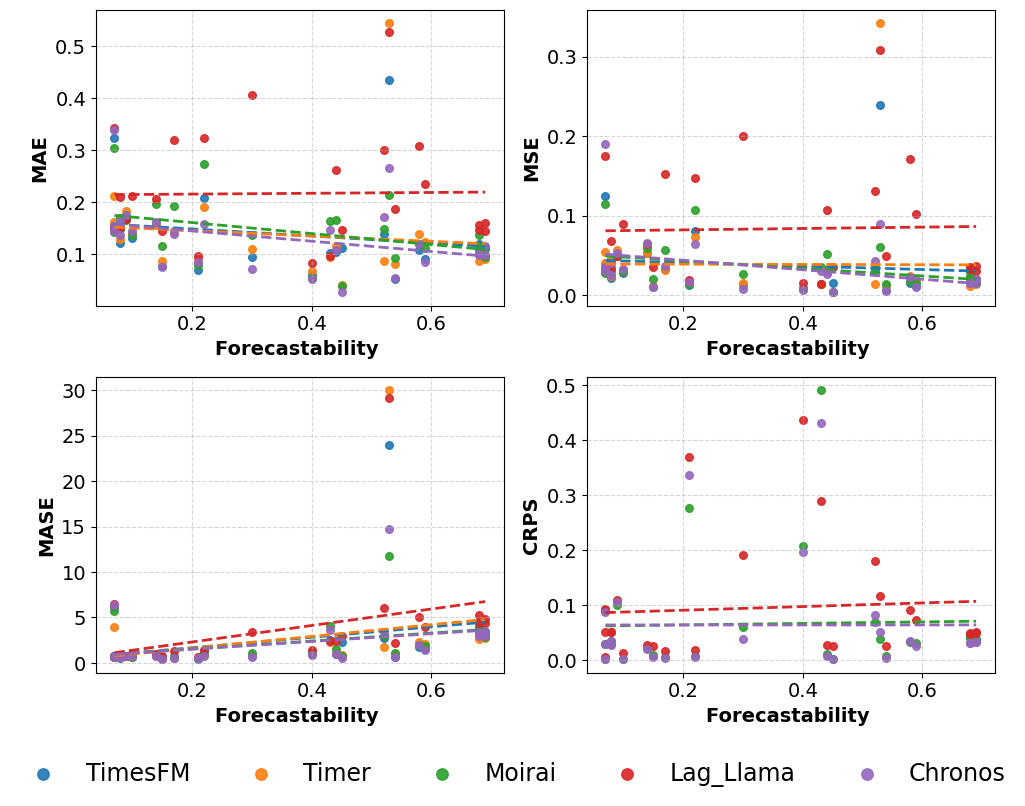



CORRELATION RESULTS
    Metric     Model  N   Slope  Pearson_r  Pearson_p  Spearman_rho  Spearman_p
mae_scaled   TimesFM 26 -0.0678    -0.1950     0.3398       -0.4695      0.0155
mae_scaled     Timer 26 -0.0514    -0.1292     0.5293       -0.5321      0.0051
mae_scaled    Moirai 26 -0.1057    -0.4152     0.0349       -0.5035      0.0087
mae_scaled Lag_Llama 26  0.0078     0.0172     0.9336       -0.0437      0.8323
mae_scaled   Chronos 26 -0.0988    -0.3514     0.0784       -0.4441      0.0230
mse_scaled   TimesFM 26 -0.0216    -0.1038     0.6139       -0.4142      0.0354
mse_scaled     Timer 26 -0.0017    -0.0062     0.9761       -0.4938      0.0103
mse_scaled    Moirai 26 -0.0475    -0.4105     0.0372       -0.4690      0.0157
mse_scaled Lag_Llama 26  0.0087     0.0280     0.8919       -0.0264      0.8981
mse_scaled   Chronos 26 -0.0595    -0.3660     0.0659       -0.4899      0.0111
      mase   TimesFM 26  5.7484     0.2908     0.1495        0.6024      0.0011
      mase     Tim

In [ ]:
# @title
# =====================================================
# 0) کتابخانه‌ها
# =====================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr, spearmanr
from google.colab import drive


# =====================================================
# 1) اتصال به Google Drive
# =====================================================

drive.mount('/content/drive')


# =====================================================
# 2) بارگذاری داده
# =====================================================

input_path = "/content/drive/MyDrive/results/paper/All_models_metrics_summary.xlsx"

df = pd.read_excel(input_path)


# =====================================================
# 3) تنظیمات
# =====================================================

all_models = ["TimesFM", "Timer", "Moirai", "Lag_Llama", "Chronos"]
metrics = ["mae_scaled", "mse_scaled","mase", "crps"]

metric_ylabel = {
    "mae_scaled": "MAE",
    "mse_scaled": "MSE",
    "mase": "MASE",
    "crps": "CRPS"
}

# رنگ هر مدل
colors = {
    "TimesFM": "#1f77b4",
    "Timer": "#ff7f0e",
    "Moirai": "#2ca02c",
    "Lag_Llama": "#d62728",
    "Chronos": "#9467bd",
}


# =====================================================
# 4) تنظیم فونت‌ها
# =====================================================

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.labelsize": 14,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 17
})


# =====================================================
# 5) لیست برای ذخیره نتایج آماری
# =====================================================

correlation_results = []


# =====================================================
# 6) شکل 2×2
# =====================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10, 8)
)

axes = axes.flatten()


# =====================================================
# 7) رسم نمودارها و محاسبه correlations
# =====================================================

for i, target_metric in enumerate(metrics):

    ax = axes[i]

    # -------------------------------------------------
    # فقط سه مدل برای CRPS
    # -------------------------------------------------

    if target_metric == "crps":
        models = [
            "Moirai",
            "Lag_Llama",
            "Chronos"
        ]
    else:
        models = all_models


    # -------------------------------------------------
    # پردازش هر مدل
    # -------------------------------------------------

    for model_name in models:

        df_model = df[
            df["model"] == model_name
        ].copy()

        # حذف missing values
        df_model = df_model.dropna(
            subset=["FCA", target_metric]
        )

        # مرتب‌سازی بر اساس FCA
        df_model = df_model.sort_values(
            by="FCA"
        )


        # حداقل تعداد داده
        if len(df_model) < 3:
            print(
                f"WARNING: Not enough data for "
                f"{target_metric} - {model_name}"
            )
            continue


        # -------------------------------------------------
        # داده‌های X و Y
        # -------------------------------------------------

        x = df_model["FCA"].values
        y = df_model[target_metric].values


        # تعداد واقعی نمونه‌ها
        n = len(x)


        # -------------------------------------------------
        # Linear Regression
        # -------------------------------------------------

        slope, intercept = np.polyfit(
            x,
            y,
            1
        )

        trend = (
            slope * x
            + intercept
        )


        # -------------------------------------------------
        # Pearson correlation + p-value
        # -------------------------------------------------

        pearson_r, pearson_p = pearsonr(
            x,
            y
        )


        # -------------------------------------------------
        # Spearman correlation + p-value
        # -------------------------------------------------

        spearman_rho, spearman_p = spearmanr(
            x,
            y
        )


        # -------------------------------------------------
        # چاپ نتایج در Colab
        # -------------------------------------------------

        print(
            f"{target_metric:12s} | "
            f"{model_name:10s} | "
            f"n={n:2d} | "
            f"Slope={slope:.3f} | "
            f"Pearson r={pearson_r:.3f} | "
            f"Pearson p={pearson_p:.4f} | "
            f"Spearman rho={spearman_rho:.3f} | "
            f"Spearman p={spearman_p:.4f}"
        )


        # -------------------------------------------------
        # ذخیره نتایج برای Excel
        # -------------------------------------------------

        correlation_results.append({
            "Metric": target_metric,
            "Model": model_name,
            "N": n,
            "Slope": slope,

            "Pearson_r": pearson_r,
            "Pearson_p": pearson_p,

            "Spearman_rho": spearman_rho,
            "Spearman_p": spearman_p
        })


        # -------------------------------------------------
        # Scatter plot
        # -------------------------------------------------

        ax.scatter(
            x,
            y,
            s=30,
            color=colors[model_name],
            alpha=0.9,
            label=model_name
        )


        # -------------------------------------------------
        # Trend line
        # -------------------------------------------------

        ax.plot(
            x,
            trend,
            color=colors[model_name],
            linestyle="--",
            linewidth=2
        )


    # =================================================
    # تنظیمات subplot
    # =================================================

    ax.set_xlabel(
        "Forecastability ",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_ylabel(
        metric_ylabel[target_metric],
        fontsize=14,
        fontweight="bold"
    )

    ax.tick_params(
        axis="both",
        labelsize=14
    )

    ax.grid(
        True,
        linestyle="--",
        alpha=0.5
    )


# =====================================================
# 8) Legend مشترک
# =====================================================

handles, labels = (
    axes[0].get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=5,
    fontsize=17,
    frameon=False,
    markerscale=1.5
)


# =====================================================
# 9) تنظیم فاصله‌ها
# =====================================================

plt.tight_layout(
    rect=[0, 0.06, 1, 1]
)


# =====================================================
# 10) ذخیره شکل PDF
# =====================================================

pdf_path = (
    "/content/drive/MyDrive/results/paper/"
    "figures/FCA_vs_AllMetrics_2x2.pdf"
)

plt.savefig(
    pdf_path,
    format="pdf",
    dpi=600,
    bbox_inches="tight"
)


# =====================================================
# 11) نمایش شکل
# =====================================================

plt.show()


# =====================================================
# 12) تبدیل نتایج آماری به DataFrame
# =====================================================

correlation_df = pd.DataFrame(
    correlation_results
)


# =====================================================
# 13) نمایش جدول نتایج
# =====================================================

print("\n")
print("=" * 100)
print("CORRELATION RESULTS")
print("=" * 100)

print(
    correlation_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# =====================================================
# 14) ذخیره نتایج آماری در Excel
# =====================================================

excel_path = (
    "/content/drive/MyDrive/results/paper/"
    "FCA_correlation_statistics.xlsx"
)

correlation_df.to_excel(
    excel_path,
    index=False
)


# =====================================================
# 15) پیام نهایی
# =====================================================

print("\n")
print("=" * 100)
print("FILES SAVED SUCCESSFULLY")
print("=" * 100)

print(f"Figure:")
print(pdf_path)

print("\nCorrelation statistics:")
print(excel_path)